In [2]:
import time, json, warnings
import numpy as np, pandas as pd
from pathlib import Path
warnings.filterwarnings("ignore")
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, matthews_corrcoef, confusion_matrix)

P = Path("processed"); B = P / "balanced"
X_val = np.load(P / "X_val.npy"); y_val = np.load(P / "y_val.npy")

sets = ["none", "class_weight", "random_over", "random_under", "smote",
        "borderline_smote", "adasyn", "under_then_smote",
        "smote_tomek", "smote_enn", "tomek_links"]

In [3]:
rows, cms = [], {}
for s in sets:
    d = np.load(B / ("none.npz" if s == "class_weight" else f"{s}.npz"))
    X, y = d["X"], d["y"]
    svm = LinearSVC(C=1.0, dual=False, max_iter=5000, random_state=42,
                    class_weight="balanced" if s == "class_weight" else None)
    t = time.time(); svm.fit(X, y); fit_s = time.time() - t

    pred = svm.predict(X_val); score = svm.decision_function(X_val)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    cms[s] = [[int(tn), int(fp)], [int(fn), int(tp)]]
    rows.append({
        "set": s, "train_rows": len(y),
        "accuracy": accuracy_score(y_val, pred),
        "precision": precision_score(y_val, pred),
        "recall_attack": recall_score(y_val, pred),
        "normal_recall": tn / (tn + fp),
        "f1": f1_score(y_val, pred),
        "macro_f1": f1_score(y_val, pred, average="macro"),
        "pr_auc": average_precision_score(y_val, score),
        "roc_auc": roc_auc_score(y_val, score),
        "mcc": matthews_corrcoef(y_val, pred),
        "FPR": fp / (fp + tn), "FNR": fn / (fn + tp),
        "iters": int(np.max(svm.n_iter_)), "fit_s": fit_s})
    print(s, "done")

results = pd.DataFrame(rows).sort_values("mcc", ascending=False)
results.round(4)

none done
class_weight done
random_over done
random_under done
smote done
borderline_smote done
adasyn done
under_then_smote done
smote_tomek done
smote_enn done
tomek_links done


,set,train_rows,accuracy,precision,recall_attack,normal_recall,f1,macro_f1,pr_auc,roc_auc,mcc,FPR,FNR,iters,fit_s
0,none,140311,0.9610,0.9683,0.9872,0.7942,0.9777,0.9122,0.9962,0.9784,0.8269,0.2058,0.0128,23,16.8852
10,tomek_links,140193,0.9610,0.9683,0.9872,0.7942,0.9777,0.9122,0.9962,0.9784,0.8269,0.2058,0.0128,22,9.0625
9,smote_enn,236452,0.9276,0.9865,0.9289,0.9191,0.9569,0.8659,0.9964,0.9791,0.7460,0.0809,0.0711,16,14.3256
8,smote_tomek,242092,0.9248,0.9870,0.9252,0.9225,0.9551,0.8620,0.9964,0.9793,0.7402,0.0775,0.0748,18,17.6650
4,smote,242568,0.9242,0.9871,0.9244,0.9227,0.9547,0.8611,0.9965,0.9793,0.7386,0.0773,0.0756,18,17.1055
2,random_over,242568,0.9242,0.9869,0.9246,0.9215,0.9547,0.8610,0.9964,0.9793,0.7382,0.0785,0.0754,20,19.9980
1,class_weight,140311,0.9234,0.9874,0.9232,0.9252,0.9542,0.8602,0.9964,0.9790,0.7376,0.0748,0.0768,16,11.6466
7,under_then_smote,76108,0.9226,0.9876,0.9220,0.9262,0.9537,0.8590,0.9964,0.9789,0.7358,0.0738,0.0780,13,3.6812
3,random_under,38054,0.9218,0.9876,0.9212,0.9262,0.9532,0.8579,0.9963,0.9786,0.7340,0.0738,0.0788,11,1.3389
5,borderline_smote,242568,0.7637,0.9917,0.7328,0.9608,0.8428,0.6836,0.9934,0.9616,0.4943,0.0392,0.2672,22,29.4816


In [4]:
results.round(4).to_csv(P / "svm_results.csv", index=False)
json.dump(cms, open(P / "svm_confusion.json", "w"))

In [6]:
lr = pd.read_csv(P / "lr_results.csv").set_index("set")
sv = results.set_index("set")
cmp = pd.DataFrame({
    "LR_mcc": lr["mcc"], "SVM_mcc": sv["mcc"],
    "LR_FNR": lr["FNR"], "SVM_FNR": sv["FNR"],
    "LR_FPR": lr["FPR"], "SVM_FPR": sv["FPR"]}).round(4)
cmp.sort_values("SVM_mcc", ascending=False)

,LR_mcc,SVM_mcc,LR_FNR,SVM_FNR,LR_FPR,SVM_FPR
set,,,,,,
none,0.8351,0.8269,0.0124,0.0128,0.1955,0.2058
tomek_links,0.8351,0.8269,0.0127,0.0128,0.1938,0.2058
smote_enn,0.7469,0.7460,0.0728,0.0711,0.0741,0.0809
smote_tomek,0.7387,0.7402,0.0776,0.0748,0.0706,0.0775
smote,0.7381,0.7386,0.0779,0.0756,0.0706,0.0773
random_over,0.7387,0.7382,0.0777,0.0754,0.0704,0.0785
class_weight,0.7372,0.7376,0.0784,0.0768,0.0704,0.0748
under_then_smote,0.7320,0.7358,0.0810,0.0780,0.0701,0.0738
random_under,0.7309,0.7340,0.0813,0.0788,0.0709,0.0738


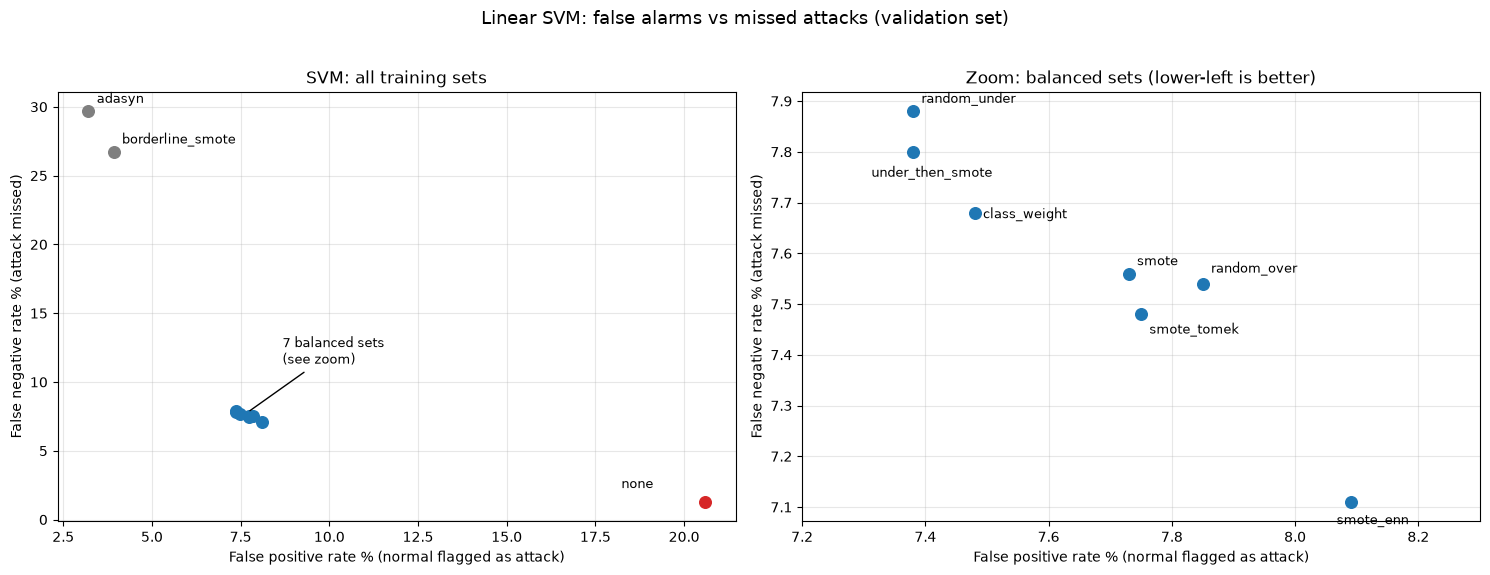

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

r = pd.read_csv(P / "svm_results.csv")
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

def draw(a, d, title, offs=None):
    offs = offs or {}
    for _, x in d.iterrows():
        c = {"none": "tab:red", "tomek_links": "tab:red",
             "borderline_smote": "tab:gray", "adasyn": "tab:gray"}.get(x["set"], "tab:blue")
        a.scatter(x["FPR"] * 100, x["FNR"] * 100, s=70, color=c, zorder=3)
        a.annotate(x["set"], (x["FPR"] * 100, x["FNR"] * 100),
                   xytext=offs.get(x["set"], (6, 6)), textcoords="offset points", fontsize=9)
    a.set_xlabel("False positive rate % (normal flagged as attack)")
    a.set_ylabel("False negative rate % (attack missed)")
    a.set_title(title); a.grid(alpha=.3)

# left: the extremes only, so labels don't overlap
draw(ax[0], r[r["set"].isin(["none", "adasyn", "borderline_smote"])],
     "SVM: all training sets", {"none": (-60, 10)})
cluster = r[~r["set"].isin(["none", "tomek_links", "adasyn", "borderline_smote"])]
ax[0].scatter(cluster["FPR"] * 100, cluster["FNR"] * 100, s=70, color="tab:blue", zorder=3)
ax[0].annotate("7 balanced sets\n(see zoom)", (7.7, 7.8), xytext=(25, 35),
               textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="-"))

# right: zoom on the balanced cluster
offs = {"smote_enn": (-10, -16), "smote_tomek": (6, -14), "smote": (6, 6),
        "random_over": (6, 8), "class_weight": (6, -4),
        "under_then_smote": (-30, -18), "random_under": (6, 6)}
draw(ax[1], cluster, "Zoom: balanced sets (lower-left is better)", offs)
ax[1].set_xlim(7.2, 8.3)

fig.suptitle("Linear SVM: false alarms vs missed attacks (validation set)", fontsize=13)
plt.tight_layout(rect=[0, .03, 1, .96])
plt.savefig(P / "svm_tradeoff.png", dpi=150); plt.show()